# Mimir v1.5 RLVR, second round: RL on traces or on direct answers?

**Question.** In the first round, GRPO on top of trace SFT (E3, macro test 0.639) only got back to plain answer-only
SFT (E1, 0.642). The diagnosis ([wiki](../wiki/pages/hrm-graph/mimir-graph-trace-sft-analysis.md)) traced most of the
loss to the trace data, not to traces as such, so the second round:

1. repaired the trace data (E2c: CLRS traces without their repeated lines) and ran the same GRPO on it (**E3c**);
2. ran the same GRPO from the answer-only model (**E3e1**), same data, settings and 200 steps.

This notebook compares the second round (E3c, E3e1) with the first (E3), using the decision rules fixed in the wiki
(section 6) before any of these results existed.

**Answer** (one seed; numbers computed below):

| Comparison | Result | Rule outcome |
| --- | --- | --- |
| E3c vs E3 (repaired vs old traces, same RL) | +0.011 macro test (95% CI +0.006 to +0.017); CLRS repeated-line algorithms on larger graphs 0.180 → 0.453; KGQA "no path, answers in facts" unchanged (0.734 → 0.731) | **E3c better**, on CLRS only |
| E3e1 vs E3c (direct answers vs traces, same RL) | E3e1 0.662 vs 0.650 macro test (+0.012, CI +0.006 to +0.018); KGQA "path in facts" 0.935 vs 0.924; GraphQA 0.825 vs 0.904 | **Answer-only SFT + RL is the better recipe on this benchmark**; traces pay only on GraphQA |
| E3e1 vs E1 / E1p (does RL add over answer-only SFT?) | +0.020 / +0.012 macro test | Yes |
| Never-scored test rows (confirmation) | E3e1 0.824 > E3c 0.809 > E3 0.797 > E1 0.772 | Same direction, so the conclusions stand (on these fewer rows the E3e1 − E3c and E3c − E3 intervals include 0) |
| Cost | E3e1's 200 GRPO steps: 27 GPU hours, answers ~22–38 tokens; E3c: 55 h, ~380–580 tokens | |
| Mimir E1 vs the best baseline E1 (same SFT, section 12) | Tie: 0.644 ± 0.002 vs Qwen3.5-4B 0.643 ± 0.008 (3 seeds each, Qwen at its tuned lr 5e-5); Mimir ahead on GraphQA (+0.05), CLRS (+0.12) and the anonymised sets (+0.06), behind on WebQSP, CWQ and CLUTRR | Not better after the same SFT; ahead only after GRPO (E3e1 0.662, one seed, no baseline RL) |

**Contents:** 1. setup · 2. the models · 3. headline scores · 4. SFT → GRPO · 5. are the differences real? ·
6. where they come from · 7. CLRS by algorithm · 8. training dynamics · 9. what E3e1 learned · 10. never-scored rows ·
11. val and headroom · 12. against the baselines (GLM cut-offs and format, the like-for-like claim) · 13. limits.

## 1. Setup

In [1]:
import json, re, sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO))
from graph_bench.eval.trace_gap_breakdown import (BENCH, KGQA, REPEAT_THRESHOLD, category, clrs_repeat_by_algo,
                                                  derivable, writes_trace)
from graph_bench.schema import read_records
from graph_bench.scoring import has_answer_line

ROOT = Path("/work/dfm/marius-ortega/dfm-hrm-graphs/mimir_bench")   # eval reports and GRPO logs
DATASETS = ["graphqa", "metaqa", "kqapro", "webqsp", "clrs", "cwq", "clutrr"]   # macro test = mean over these 7
VAL_DATASETS = ["graphqa", "metaqa", "kqapro", "webqsp", "clrs"]
pd.set_option("display.width", 200, "display.max_columns", 30)

# report file stems per model: test (named), anonymised test, never-scored test rows, val pass@16, OSM; GRPO run dir.
# Trace models and GRPO models are scored with 3,072 answer tokens (_t3k), answer-only SFT models with 1,024.
T3K = dict(named="named_t3k", anon="anon_t3k", hold="holdback_t3k", val="val_pass16_t2k")
ARMS = {
    "E1":   dict(dir="e1",   named="named", anon="anon", hold="holdback", val="val_pass16", osm=None, grpo=None,
                 recipe="answer-only", stage="SFT"),
    "E1p":  dict(dir="e1p",  named="named", anon="anon", hold="holdback", val=None, osm=None, grpo=None,
                 recipe="answer-only", stage="SFT"),
    "E2":   dict(dir="e2",   **T3K, osm="osm_t3k", grpo=None, recipe="old traces", stage="SFT"),
    "E2c":  dict(dir="e2c",  **T3K, osm=None, grpo=None, recipe="repaired traces", stage="SFT"),
    "E2p":  dict(dir="e2p",  **T3K, osm=None, grpo=None, recipe="repaired traces", stage="SFT"),
    "E3":   dict(dir="e3",   **T3K, osm="osm_t3k", grpo="e3_grpo_e2", recipe="old traces", stage="GRPO"),
    "E3c":  dict(dir="e3c",  **T3K, osm="osm_t3k", grpo="e3c_grpo_e2c", recipe="repaired traces", stage="GRPO"),
    "E3e1": dict(dir="e3e1", **T3K, osm="osm_t3k", grpo="e3_grpo_e1", recipe="answer-only", stage="GRPO"),
}

def summary(arm, kind):
    return json.load(open(ROOT / ARMS[arm]["dir"] / "mimir15" / f"{ARMS[arm][kind]}.json"))["summary"]

_samples = {}
def samples(arm, kind):
    key = (arm, kind)
    if key not in _samples:
        path = ROOT / ARMS[arm]["dir"] / "mimir15" / f"{ARMS[arm][kind]}.samples.jsonl"
        _samples[key] = [json.loads(line) for line in open(path, encoding="utf-8")]
    return _samples[key]

# chart style: one colour per recipe (validated palette: CVD-safe for 3 series), E1 as a neutral reference
COLOR = {"answer-only": "#2a78d6", "repaired traces": "#eb6834", "old traces": "#1baf7a"}
REF, INK, INK2, GRID = "#8a8985", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.dpi": 110})

def bold_best(df, rules, axis=0, digits=3):
    """Styled table with the best value in bold. rules: [(columns, "max" | "min")]; axis=0 compares down each column
    (rows are models), axis=1 across the given columns of each row (columns are models). Ties at the shown precision
    are all bold."""
    sty = df.style.format(precision=digits, na_rep="")
    ints = [c for c in df.columns if c in ("n", "answer tokens")]
    if ints:
        sty = sty.format("{:.0f}", subset=ints, na_rep="")
    def mark(values, best):
        v = pd.to_numeric(values, errors="coerce").round(digits)
        target = v.max() if best == "max" else v.min()
        return ["font-weight: bold" if pd.notna(x) and x == target else "" for x in v]
    for cols, best in rules:
        sty = sty.apply(mark, axis=axis, subset=list(cols), best=best)
    return sty

## 2. The models

| Model | Starts from | Trained on | Role here |
| --- | --- | --- | --- |
| E1 | base Mimir v1.5 | SFT on `Answer: X.` only (17,917 rows) | answer-only reference |
| E1p | base | E1 + 523 WebQSP questions without a gold path | answer-only control for E2p |
| E2 | base | SFT on trace + answer (same questions as E1) | old traces, before RL |
| E2c | base | E2 with CLRS repeated trace lines merged | repaired traces, before RL |
| E2p | base | E2c + the 523 questions, answer line only | not chosen for RL (val rule) |
| **E3** | E2 | GRPO, 200 steps | **first round** |
| **E3c** | E2c | same GRPO as E3 | **second round, traces** |
| **E3e1** | E1 | same GRPO as E3 | **second round, direct answers** |

GRPO, identical for the three runs (checked in the VeRL configs): `verl/train.parquet`, reward 1 if the final answer
is right, 16 questions × 8 samples per step, answers up to 2,048 tokens, lr 1e-5, LoRA r32, groups where all 8
samples score the same dropped, no KL term. So **E3c − E3 measures the trace repair, and E3e1 − E3c measures traces
against direct answers**, each under the same RL budget.

Test = the fixed 1,000-per-file subset used by every earlier report (12 files, 7 datasets); macro = mean of the 7
dataset accuracies, greedy decoding, one seed. Training sets: GraphQA, MetaQA 1-2 hop, KQA Pro, WebQSP, CLRS; CWQ,
CLUTRR and OSM are never trained on.

## 3. Headline scores

In [2]:
rows = []
for arm, a in ARMS.items():
    s = summary(arm, "named")
    r = {"model": arm, "recipe": a["recipe"], "stage": a["stage"], "macro test": s["macro_acc"],
         "macro anonymised": summary(arm, "anon")["macro_acc"], "macro never-scored": summary(arm, "hold")["macro_acc"]}
    if a["val"]:
        v = summary(arm, "val")
        r["val pass@1"] = np.mean([v[d]["pass@1"] for d in VAL_DATASETS])
        r["val pass@16"] = np.mean([v[d]["pass@16"] for d in VAL_DATASETS])
    r["OSM"] = summary(arm, "osm")["osm"]["acc"] if a["osm"] else np.nan
    r.update({d: s[d]["acc"] for d in DATASETS})
    rows.append(r)
headline = pd.DataFrame(rows).set_index("model")
bold_best(headline, [(headline.select_dtypes("number").columns, "max")])   # best per column

,recipe,stage,macro test,macro anonymised,macro never-scored,val pass@1,val pass@16,OSM,graphqa,metaqa,kqapro,webqsp,clrs,cwq,clutrr
model,,,,,,,,,,,,,,,
E1,answer-only,SFT,0.642,0.814,0.772,0.803,0.904,,0.804,0.851,0.708,0.781,0.482,0.675,0.192
E1p,answer-only,SFT,0.650,0.817,0.808,,,,0.806,0.850,0.711,0.798,0.552,0.677,0.156
E2,old traces,SFT,0.583,0.750,0.709,0.781,0.905,0.046,0.895,0.791,0.670,0.712,0.366,0.529,0.118
E2c,repaired traces,SFT,0.616,0.764,0.761,0.800,0.904,,0.905,0.799,0.663,0.733,0.493,0.570,0.148
E2p,repaired traces,SFT,0.610,0.802,0.789,0.804,0.905,,0.902,0.787,0.662,0.759,0.497,0.662,0.000
E3,old traces,GRPO,0.639,0.806,0.797,0.871,0.928,0.100,0.904,0.817,0.699,0.761,0.483,0.652,0.154
E3c,repaired traces,GRPO,0.650,0.810,0.809,0.877,0.912,0.066,0.904,0.821,0.689,0.769,0.532,0.656,0.176
E3e1,answer-only,GRPO,0.662,0.822,0.824,0.850,0.896,0.066,0.825,0.853,0.713,0.793,0.586,0.683,0.179


- **E3e1 has the best macro on every test view**: test 0.662, anonymised 0.822, never-scored 0.824. E3c is second on
  test (0.650, tied with E1p) and on never-scored rows (0.809).
- **Per dataset, traces win only on GraphQA** (E3c 0.904 vs E3e1 0.825). E3e1 leads on MetaQA, KQA Pro, WebQSP, CLRS and CWQ;
  CLUTRR is a tie (0.176 vs 0.179).
- **Val disagrees** (E3c 0.877 vs E3e1 0.850 pass@1): val has only the 5 training datasets, so GraphQA weighs a fifth
  of its macro against a seventh of the test macro (section 11).
- **OSM** (unseen, near zero for everyone): E3 0.100, E3c 0.066, E3e1 0.066. E3e1 has the highest F1 (0.49): it
  lists POIs that are partly right.

## 4. What GRPO adds to each starting point

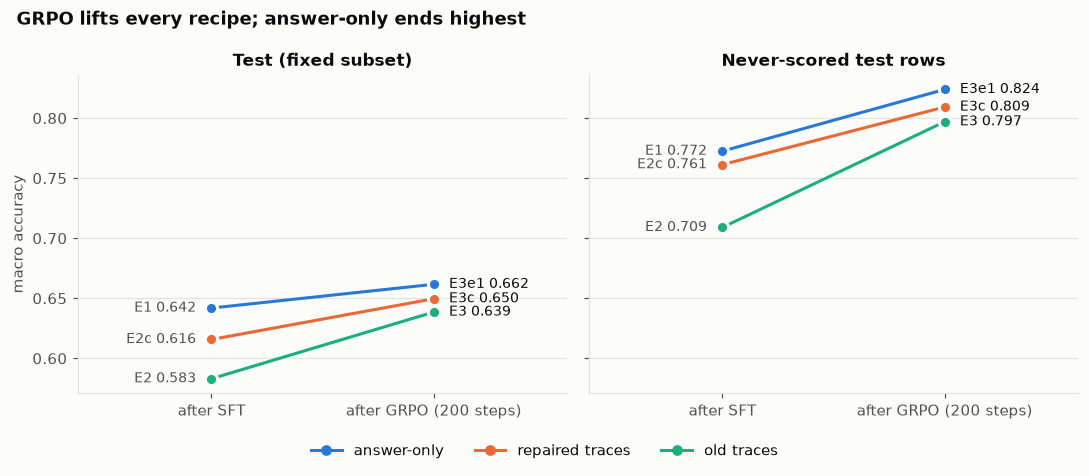

In [3]:
pairs = [("E1", "E3e1", "answer-only"), ("E2c", "E3c", "repaired traces"), ("E2", "E3", "old traces")]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, col, title in zip(axes, ["macro test", "macro never-scored"], ["Test (fixed subset)", "Never-scored test rows"]):
    for sft, rl, recipe in pairs:
        y = [headline.loc[sft, col], headline.loc[rl, col]]
        ax.plot([0, 1], y, color=COLOR[recipe], lw=2, marker="o", ms=8, mec="#fcfcfb", mew=2, zorder=3)
        ax.annotate(f"{sft} {y[0]:.3f}", (0, y[0]), xytext=(-10, 0), textcoords="offset points", ha="right",
                    va="center", color=INK2, fontsize=9)
        ax.annotate(f"{rl} {y[1]:.3f}", (1, y[1]), xytext=(10, 0), textcoords="offset points", ha="left",
                    va="center", color=INK, fontsize=9)
    ax.set_xticks([0, 1], ["after SFT", "after GRPO (200 steps)"]); ax.set_xlim(-0.6, 1.6); ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("macro accuracy")
handles = [plt.Line2D([], [], color=COLOR[r], lw=2, marker="o", label=r) for r in COLOR]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("GRPO lifts every recipe; answer-only ends highest", x=0.02, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

- **Before RL, answer-only was ahead** (E1 0.642 vs E2c 0.616). GRPO adds +0.056 to E2 and +0.034 to E2c but only
  +0.020 to E1, so the gap narrows but does not close: E3e1 ends 0.012 above E3c.
- **The trace repair survives RL**: E3c starts 0.033 above E3's start and ends 0.011 above E3. GRPO had repaired part of the old
  traces' damage by itself, so part of the head start is spent.

## 5. Are the differences real?

Paired bootstrap over test rows (resampled within each dataset, 2,000 draws), on the macro difference. This
covers the sampling of test questions only, **not** training noise: there is one seed per model. The wiki's rule
treats macro differences under 0.02 as inconclusive on their own (E1 and E1p, with identical CLRS rows, differ
by 0.088 on CLRS test).

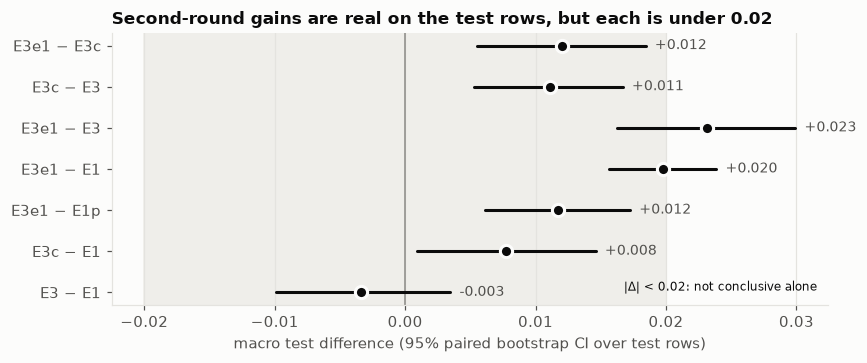

,macro,CI 2.5%,CI 97.5%
difference,,,
E3e1 − E3c,0.0120,0.0055,0.0184
E3c − E3,0.0111,0.0053,0.0167
E3e1 − E3,0.0231,0.0163,0.0299
E3e1 − E1,0.0198,0.0156,0.0239
E3e1 − E1p,0.0117,0.0061,0.0172
E3c − E1,0.0077,0.0009,0.0146
E3 − E1,-0.0034,-0.0099,0.0035


In [4]:
def acc_matrix(kind, arms):
    rows = [samples(a, kind) for a in arms]
    ids = [r["id"] for r in rows[0]]
    assert all([r["id"] for r in rs] == ids for rs in rows), "reports differ in rows"
    ds = np.array([r["dataset"] for r in rows[0]])
    return ds, {a: np.array([float(r["acc"][0]) for r in rs]) for a, rs in zip(arms, rows)}

def paired_bootstrap(ds, acc, a, b, draws=2000, seed=0):
    rng = np.random.default_rng(seed)
    groups = [np.where(ds == d)[0] for d in sorted(set(ds))]
    point = np.mean([(acc[a][g] - acc[b][g]).mean() for g in groups])
    boot = np.zeros(draws)
    for g in groups:
        pick = g[rng.integers(0, len(g), (draws, len(g)))]
        boot += (acc[a][pick] - acc[b][pick]).mean(1) / len(groups)
    return point, *np.percentile(boot, [2.5, 97.5])

ds_test, acc_test = acc_matrix("named", list(ARMS))
comparisons = [("E3e1", "E3c"), ("E3c", "E3"), ("E3e1", "E3"), ("E3e1", "E1"), ("E3e1", "E1p"), ("E3c", "E1"),
               ("E3", "E1")]
boot = pd.DataFrame([(f"{a} − {b}", *paired_bootstrap(ds_test, acc_test, a, b)) for a, b in comparisons],
                    columns=["difference", "macro", "CI 2.5%", "CI 97.5%"]).set_index("difference")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axvspan(-0.02, 0.02, color="#efeeea", zorder=0, label="|Δ| < 0.02: not conclusive alone")
ax.axvline(0, color=REF, lw=1)
for i, (name, r) in enumerate(boot.iterrows()):
    ax.plot([r["CI 2.5%"], r["CI 97.5%"]], [i, i], color=INK, lw=2, solid_capstyle="round")
    ax.plot(r["macro"], i, "o", color=INK, ms=8, mec="#fcfcfb", mew=2)
    ax.annotate(f"{r['macro']:+.3f}", (r["CI 97.5%"], i), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(boot)), boot.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("macro test difference (95% paired bootstrap CI over test rows)")
ax.set_title("Second-round gains are real on the test rows, but each is under 0.02", loc="left")
ax.legend(loc="lower right", fontsize=8); fig.tight_layout(); plt.show()
boot.round(4)

- **E3e1 > E3c and E3c > E3 hold on the test rows** (both intervals exclude 0), but each is about +0.01. By the
  rule, the macro alone does not settle either comparison: the targeted rows (section 6) and the never-scored rows
  (section 10) have to agree. The targeted rows agree; the never-scored rows agree in direction, with wider intervals.
- **Training noise is unmeasured.** A second seed of E3c and E3e1 would be needed to rule out a +0.01 swing
  from RL noise alone.

## 6. Where the differences come from

Test rows split into the groups of the first-round diagnosis (`graph_bench/eval/trace_gap_breakdown.py`): KGQA rows by
what the prompt's facts allow, compositions not seen in SFT, CLRS algorithms whose trace was mostly repeated lines,
CLUTRR, GraphQA. "Δ macro" is each group's share of the model's macro difference to E3c (sums to the total).

In [5]:
REPEATED = {algo for algo, share in clrs_repeat_by_algo().items() if share >= REPEAT_THRESHOLD}
_records = {}
def record(src, rid):
    if src not in _records:
        _records[src] = {r.id: r for r in read_records(BENCH / f"{src}.jsonl")}
    return _records[src][rid]

def row_table(kind, arms):
    """One row per test question: group labels from the bench record, then acc / no-Answer-line / length per model."""
    reports = [samples(a, kind) for a in arms]
    out = []
    for i in range(len(reports[0])):
        rows = [rep[i] for rep in reports]
        src = next(r["source"] for r in rows if "source" in r)
        base = dict(rows[0], source=src)
        rec = record(src, base["id"])
        d = dict(id=base["id"], dataset=base["dataset"], task=base["task"], split=src.split("/")[1],
                 group=category(base, rec, REPEATED), allows=derivable(rec) if base["dataset"] in KGQA else None)
        for a, r in zip(arms, rows):
            g = r["generations"][0]
            d[a] = float(r["acc"][0]); d[f"{a} no answer"] = not has_answer_line(g); d[f"{a} trace"] = writes_trace(g)
            d[f"{a} chars"] = len(g)
        out.append(d)
    return pd.DataFrame(out)

MAIN = ["E1", "E1p", "E2", "E2c", "E3", "E3c", "E3e1"]
test = row_table("named", MAIN)

def group_table(df, arms, ref):
    per_ds = df["dataset"].value_counts(); n_ds = len(per_ds)
    weight = 1 / df["dataset"].map(per_ds) / n_ds              # each row's weight in the macro
    g = df.groupby("group")
    t = pd.DataFrame({"n": g.size(), **{a: g[a].mean() for a in arms}})
    for a in arms:
        if a != ref:
            t[f"Δ macro {a}−{ref}"] = ((df[a] - df[ref]) * weight).groupby(df["group"]).sum()
    return t

groups = group_table(test, MAIN, "E3c")
groups.loc["total (macro)"] = [np.nan] + [headline.loc[a, "macro test"] for a in MAIN] + \
    [groups[c].sum() for c in groups.columns if c.startswith("Δ")]
bold_best(groups, [(MAIN, "max")], axis=1)   # best model per row

,n,E1,E1p,E2,E2c,E3,E3c,E3e1,Δ macro E1−E3c,Δ macro E1p−E3c,Δ macro E2−E3c,Δ macro E2c−E3c,Δ macro E3−E3c,Δ macro E3e1−E3c
group,,,,,,,,,,,,,,
CLRS OOD size: other algorithms,600,0.102,0.145,0.043,0.092,0.142,0.117,0.158,-0.001,0.001,-0.003,-0.001,0.001,0.002
CLRS OOD size: repeated-line traces,300,0.433,0.493,0.093,0.420,0.180,0.453,0.553,-0.000,0.001,-0.008,-0.001,-0.006,0.002
CLRS test: other algorithms,665,0.635,0.746,0.647,0.662,0.741,0.732,0.803,-0.005,0.001,-0.004,-0.004,0.000,0.004
CLRS test: repeated-line traces,335,0.904,0.946,0.630,0.940,0.851,0.949,0.952,-0.001,-0.000,-0.008,-0.000,-0.002,0.000
CLUTRR (held out),1000,0.192,0.156,0.118,0.148,0.154,0.176,0.179,0.002,-0.003,-0.008,-0.004,-0.003,0.000
GraphQA,2324,0.804,0.806,0.895,0.905,0.904,0.904,0.825,-0.014,-0.014,-0.001,0.000,-0.000,-0.011
"KGQA: MetaQA 1-2 hop / KQA Pro, path in prompt",1430,0.958,0.959,0.966,0.959,0.973,0.964,0.962,-0.001,-0.001,0.000,-0.001,0.002,-0.000
"KGQA: WebQSP, path in prompt",710,0.901,0.915,0.834,0.855,0.873,0.886,0.914,0.002,0.003,-0.005,-0.003,-0.001,0.003
KGQA: gold path not in the prompt,1582,0.460,0.467,0.327,0.345,0.414,0.410,0.464,0.010,0.012,-0.018,-0.014,0.001,0.011


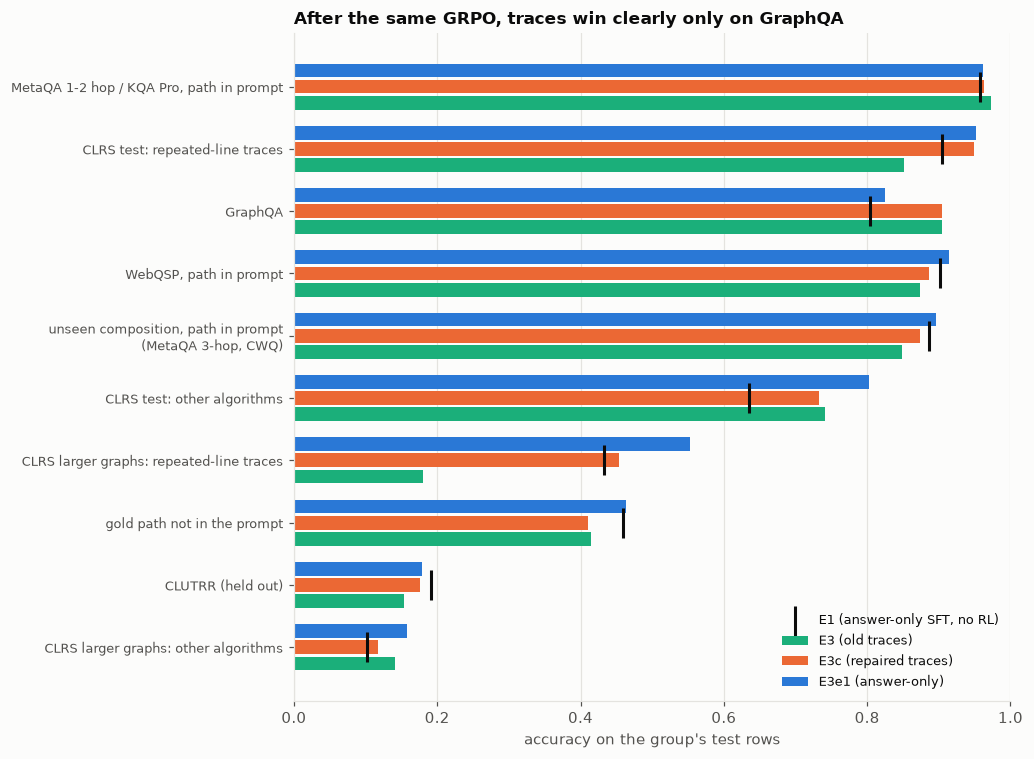

In [6]:
order = groups.drop("total (macro)").sort_values("E3c").index
short = {g: g.replace("KGQA: ", "").replace(" (MetaQA 3-hop, CWQ)", "\n(MetaQA 3-hop, CWQ)")
         .replace("path in prompt, composition not in SFT data", "unseen composition, path in prompt")
         .replace("CLRS OOD size", "CLRS larger graphs") for g in order}
show = [("E3", "old traces"), ("E3c", "repaired traces"), ("E3e1", "answer-only")]
fig, ax = plt.subplots(figsize=(9.5, 7))
h = 0.26
for k, (arm, recipe) in enumerate(show):
    y = np.arange(len(order)) + (k - 1) * h
    ax.barh(y, groups.loc[order, arm], height=h - 0.04, color=COLOR[recipe], label=f"{arm} ({recipe})", zorder=2)
ax.scatter(groups.loc[order, "E1"], np.arange(len(order)), marker="|", s=380, color=INK, lw=2, zorder=3,
           label="E1 (answer-only SFT, no RL)")
ax.set_yticks(np.arange(len(order)), [short[g] for g in order], fontsize=8.5); ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False); ax.set_xlabel("accuracy on the group's test rows")
ax.set_title("After the same GRPO, traces win clearly only on GraphQA", loc="left")
ax.legend(loc="lower right", fontsize=8.5); fig.tight_layout(); plt.show()

**E3c vs E3 (step 4: does RL on repaired traces beat RL on the old ones?).**
- **Targeted CLRS rows improve clearly**: the four repeated-line algorithms on larger graphs go 0.180 → 0.453 (E1 0.433),
  and rows that never reach an `Answer:` line fall 0.250 → 0.127. CLRS test, other algorithms: E3 0.741, E3c 0.732.
- **The other targeted row does not move**: KGQA "no path, answers in facts" 0.734 → 0.731 (E1 0.790). The repair
  did not touch it: neither E2 nor E2c saw such questions in SFT, and both GRPO runs saw the same 817.
- **Outcome under the rule:** E3c is better, from CLRS. The macro does not drop (+0.011).

**E3e1 vs E3c (step 5, headline).**
- **E3c's whole remaining deficit is in questions a trace cannot handle**: KGQA without a gold path in the facts
  (0.410 vs 0.464, −0.011 of macro), unseen compositions (0.873 vs 0.896) and WebQSP with a path (0.886 vs 0.914).
  These are dead-end traces, a missing hop and long fact lists copied wrong, the same causes as in round 1, now smaller.
- **On computation, traces win only on GraphQA**: E3c +0.011 macro over E3e1, the one group where the trace does work
  the answer needs. On CLRS, E3e1 is level or ahead even on the repeated-line algorithms (larger graphs 0.553 vs 0.453).
- **KGQA "path in facts"** (reasoning over the graph): E3e1 0.935, E3c 0.924, E1 0.928 (table below). Rule 1 of step 5
  applies: E3e1 ≥ E3c and not behind there, so **answer-only SFT + RL is the better recipe on this benchmark; traces
  are justified only for GraphQA-like computation tasks.**

In [7]:
kg = test[test["allows"].notna()]
allows = kg.groupby("allows")[MAIN].mean()
allows.insert(0, "n", kg.groupby("allows").size())
bold_best(allows, [(MAIN, "max")], axis=1)

,n,E1,E1p,E2,E2c,E3,E3c,E3e1
allows,,,,,,,,
"no path, answers in facts",718,0.790,0.804,0.578,0.621,0.734,0.731,0.798
not all answers in facts,864,0.185,0.188,0.118,0.116,0.148,0.144,0.186
path in facts,2748,0.928,0.931,0.884,0.896,0.920,0.924,0.935


## 7. CLRS by algorithm

In [8]:
clrs = test[test["dataset"] == "clrs"]
share = clrs_repeat_by_algo()
algo = clrs.groupby(["task", "split"])[["E2", "E2c", "E3", "E3c", "E3e1", "E1"]].mean().unstack("split")
algo = algo.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
algo.insert(0, ("", "repeated lines"), pd.Series(share))
algo = algo.sort_values(("", "repeated lines"), ascending=False)
bold_best(algo, [([c for c in algo.columns if c[0] == split], "max") for split in ("test", "test_ood")], axis=1, digits=2)

- **The repair worked on the algorithms it targeted**: SCC test 0.72 (E3) → 0.91 (E3c), articulation points 0.82 →
  0.96; on larger graphs articulation points 0.23 → 0.65, SCC 0.06 → 0.38.
- **dfs is the cost of the repair**: dfs test E3 0.88, E3c 0.45, E2c 0.24. Its state changes at most steps,
  and in round 1 the trace helped there. Merging repeated lines changed its trace into
  a list of the steps where a value changes, losing the step count that made the trace useful. topological_sort, the other
  trace-friendly algorithm, held up (0.87 → 0.88).
- **E3e1 is the best or tied on 9 of 12 algorithms on test** (behind on SCC, dfs, bfs) and on 6 of the 9 measured on
  larger graphs. Larger graphs remain hard for every model: outside the four repeated-line algorithms, every model scores 0.04–0.16.

## 8. Training dynamics

From the VeRL logs (`<run>/train.log`). In-training val = VeRL's own greedy pass on `verl/val.parquet` (about 60
questions per dataset, every 25 steps). E3c was resumed at step 175 after a crash (2026-11-19); the steps it redid
are taken from the second attempt.

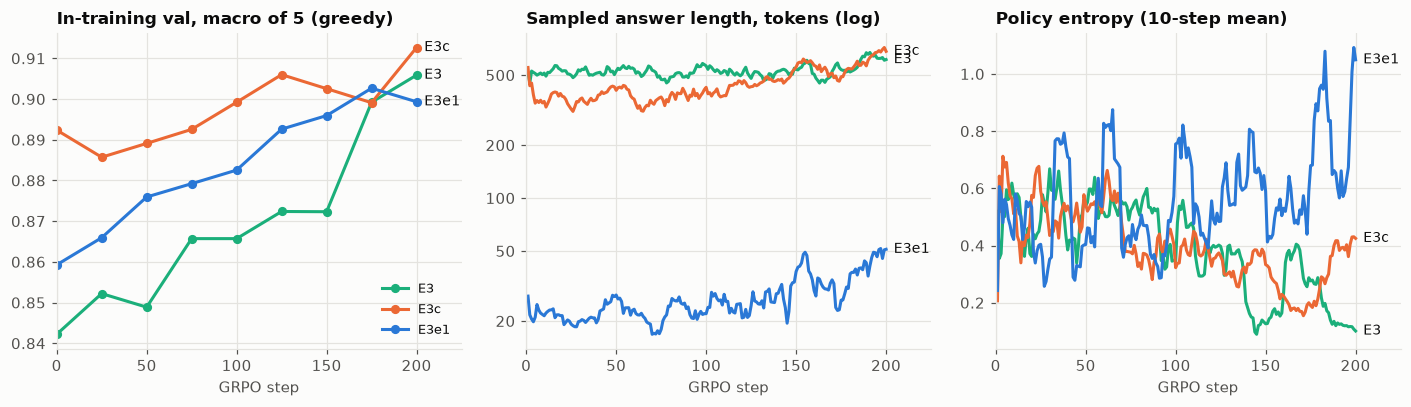

,GPU hours (200 steps),min / step,"answer tokens, steps 1-50","answer tokens, steps 151-200",train reward (kept groups)
E3,51.75,15.52,521.91,563.89,0.64
E3c,55.05,16.51,378.47,582.68,0.63
E3e1,26.67,8.00,22.27,37.65,0.58


In [9]:
STEP = re.compile(r"step:(\d+) - (.*)")
def grpo_log(run):
    steps = {}
    for line in open(ROOT / run / "train.log", errors="replace"):
        m = STEP.search(line)
        if not m:
            continue
        d = {}
        for kv in m.group(2).split(" - "):
            k, _, v = kv.rpartition(":")
            try:
                d[k.strip()] = float(v.strip().replace("np.float64(", "").rstrip(")"))
            except ValueError:
                pass
        steps[int(m.group(1))] = d                     # a redone step keeps its last attempt
    return pd.DataFrame.from_dict(steps, orient="index").sort_index()

runs = {arm: grpo_log(ARMS[arm]["grpo"]) for arm in ["E3", "E3c", "E3e1"]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for arm, log in runs.items():
    c = COLOR[ARMS[arm]["recipe"]]
    val_cols = [f"val-core/{d}/acc/mean@1" for d in VAL_DATASETS]
    v = log[val_cols].dropna().mean(axis=1)
    axes[0].plot(v.index, v.values, color=c, lw=2, marker="o", ms=5, label=arm)
    axes[1].plot(log.index, log["response_length/mean"].rolling(10, min_periods=1).mean(), color=c, lw=2, label=arm)
    axes[2].plot(log.index, log["actor/entropy"].rolling(10, min_periods=1).mean(), color=c, lw=2, label=arm)
    for ax, y in ((axes[0], v.iloc[-1]), (axes[1], log["response_length/mean"].iloc[-10:].mean()),
                  (axes[2], log["actor/entropy"].iloc[-10:].mean())):
        ax.annotate(arm, (200, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
axes[0].set_title("In-training val, macro of 5 (greedy)", loc="left")
axes[1].set_title("Sampled answer length, tokens (log)", loc="left"); axes[1].set_yscale("log")
axes[1].set_yticks([20, 50, 100, 200, 500], ["20", "50", "100", "200", "500"]); axes[1].minorticks_off()
axes[2].set_title("Policy entropy (10-step mean)", loc="left")
for ax in axes:
    ax.set_xlabel("GRPO step"); ax.set_xlim(0, 225)
axes[0].legend(loc="lower right", fontsize=8.5); fig.tight_layout(); plt.show()

cost = pd.DataFrame({arm: {"GPU hours (200 steps)": log["timing_s/step"].sum() / 3600,
                           "min / step": log["timing_s/step"].mean() / 60,
                           "answer tokens, steps 1-50": log.loc[1:50, "response_length/mean"].mean(),
                           "answer tokens, steps 151-200": log.loc[151:200, "response_length/mean"].mean(),
                           "train reward (kept groups)": log["critic/score/mean"].mean()} for arm, log in runs.items()}).T
bold_best(cost, [(["GPU hours (200 steps)", "min / step"], "min")], digits=2)   # cheapest bold

- **E3e1 costs half the GPU time** (27 h vs 55 h for E3c, 52 h for E3): its answers are ~20–40 tokens against ~400–600, so each step's
  rollout is short. The remaining time per step is mostly resampling to fill the batch after uniform groups are dropped.
- **E3e1's answers grow from ~22 to ~38 tokens and its entropy rises** (50-step means 0.48 → 0.73). It is not starting
  to write traces (section 9: none of its test answers has one); it lists more entities per answer.
- **E3c's answers grow too** (~380 → ~580 tokens, mostly in its last 75 steps, with a dip in the training reward);
  E3's grew less (~520 → ~560).
- **In-training val**: E3c 0.892 → 0.913, E3e1 0.859 → 0.899, E3 0.842 → 0.906. E3c starts near E3's end point, so RL
  has less to add.

## 9. What E3e1 learned

In [10]:
def max_repeat(g):
    items = [x.strip().rstrip(".") for x in g.split("Answer:")[-1].split("|")]
    return max((items.count(x) for x in set(items) if x), default=0)

behaviour = pd.DataFrame({arm: {
    "writes a trace (test)": test[f"{arm} trace"].mean(),
    "no Answer line (test)": test[f"{arm} no answer"].mean(),
    "mean answer chars, WebQSP + CWQ": test.loc[test["dataset"].isin(["webqsp", "cwq"]), f"{arm} chars"].mean(),
    "WebQSP + CWQ answers listing one item ≥ 5 times": np.mean([max_repeat(r["generations"][0]) >= 5
        for r in samples(arm, "named") if r["dataset"] in ("webqsp", "cwq")]),
} for arm in ["E1", "E3", "E3c", "E3e1"]}).T
display(bold_best(behaviour, [(["no Answer line (test)", "WebQSP + CWQ answers listing one item ≥ 5 times"], "min")]))

worst = sorted((r for r in samples("E3e1", "named") if r["dataset"] in ("webqsp", "cwq")),
               key=lambda r: -max_repeat(r["generations"][0]))[:2]
for r in worst:
    print(f"{r['id']}  gold={r['gold'][:4]}{'...' if len(r['gold']) > 4 else ''}\n  E3e1: {r['generations'][0][:240]}...\n")

,writes a trace (test),no Answer line (test),"mean answer chars, WebQSP + CWQ",WebQSP + CWQ answers listing one item ≥ 5 times
E1,0.000,0.002,94.382,0.009
E3,0.998,0.028,598.572,0.000
E3c,0.998,0.023,605.705,0.000
E3e1,0.000,0.002,178.812,0.009


webqsp/test/WebQTest-779  gold=['Jalisco', 'San Francisco', 'Tijuana']
  E3e1: Answer: Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca | Oaxaca ...

webqsp/test/WebQTest-125  gold=['Isaac', 'Ishbak', 'Ishmael', 'Jokshan']...
  E3e1: Answer: Isaac | Ishmael | Ishbak | Jokshan | Midian | Jakarta | Jakarta | Jakarta | Midian | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta | Jakarta...



- **E3e1 stays a direct-answer model**: no trace, and missing `Answer:` lines as rare as E1's (0.2%). Its gain over
  E1 comes from better answers in the same one-line format (CLRS +0.10, WebQSP +0.012, KGQA "path in facts" +0.007).
- **Its WebQSP / CWQ answers are twice as long as E1's** (179 vs 94 characters): it lists more entities on
  multi-answer questions, which the reward pays for. Lists that loop on one item (examples above) are not new: E1 has
  them on 1.0% of these rows, E3e1 on 0.9%.

## 10. Confirmation on never-scored test rows

The 3,559 test rows outside the 1,000-per-file subset (CWQ 2,531, WebQSP 628, CLRS test 200, GraphQA fresh / large
100 each), which no model was scored on before, and which played no part in designing the fixes. Macro over the 4 datasets present.

In [11]:
hold = row_table("hold", MAIN)
hold_groups = group_table(hold, MAIN, "E3c")
hold_groups.loc["total (macro)"] = [np.nan] + [headline.loc[a, "macro never-scored"] for a in MAIN] + \
    [hold_groups[c].sum() for c in hold_groups.columns if c.startswith("Δ")]
ds_hold, acc_hold = acc_matrix("hold", MAIN)
display(bold_best(hold_groups, [(MAIN, "max")], axis=1))
pd.DataFrame([(f"{a} − {b}", *paired_bootstrap(ds_hold, acc_hold, a, b)) for a, b in comparisons],
             columns=["difference", "macro", "CI 2.5%", "CI 97.5%"]).set_index("difference").round(4)

,n,E1,E1p,E2,E2c,E3,E3c,E3e1,Δ macro E1−E3c,Δ macro E1p−E3c,Δ macro E2−E3c,Δ macro E2c−E3c,Δ macro E3−E3c,Δ macro E3e1−E3c
group,,,,,,,,,,,,,,
CLRS test: other algorithms,135,0.704,0.837,0.689,0.726,0.822,0.815,0.874,-0.019,0.004,-0.021,-0.015,0.001,0.010
CLRS test: repeated-line traces,65,0.892,0.938,0.523,0.923,0.754,0.954,0.985,-0.005,-0.001,-0.035,-0.003,-0.016,0.003
GraphQA,200,0.815,0.825,0.920,0.920,0.925,0.920,0.860,-0.026,-0.024,0.000,0.000,0.001,-0.015
"KGQA: WebQSP, path in prompt",448,0.924,0.942,0.862,0.884,0.915,0.913,0.938,0.002,0.005,-0.009,-0.005,0.000,0.004
KGQA: gold path not in the prompt,1758,0.574,0.575,0.450,0.460,0.540,0.527,0.575,0.010,0.012,-0.020,-0.014,0.003,0.010
"KGQA: path in prompt, composition not in SFT data (MetaQA 3-hop, CWQ)",953,0.873,0.889,0.695,0.737,0.839,0.855,0.888,0.002,0.003,-0.015,-0.011,-0.001,0.003
total (macro),,0.772,0.808,0.709,0.761,0.797,0.809,0.824,-0.037,-0.001,-0.100,-0.048,-0.012,0.015


,macro,CI 2.5%,CI 97.5%
difference,,,
E3e1 − E3c,0.0146,-0.0020,0.0314
E3c − E3,0.0123,-0.0060,0.0299
E3e1 − E3,0.0269,0.0094,0.0445
E3e1 − E1,0.0514,0.0363,0.0668
E3e1 − E1p,0.0160,-0.0004,0.0329
E3c − E1,0.0367,0.0172,0.0567
E3 − E1,0.0245,0.0044,0.0454


- **Every conclusion keeps its direction**: E3c > E3 (CLRS repeated-line rows 0.754 → 0.954), E3e1 > E3c on the
  macro (+0.015, larger than on the fixed subset) and on every KGQA group, E3c ahead on GraphQA.
- **But these rows are fewer and cover only 4 datasets**, so the E3e1 − E3c and E3c − E3 intervals include 0. Step 6
  requires the same direction, which holds: the step-4 and step-5 conclusions stand.

## 11. Val and the headroom left

In [12]:
val = pd.DataFrame({arm: {**{f"{d} pass@1": summary(arm, "val")[d]["pass@1"] for d in VAL_DATASETS},
                          "macro pass@1": headline.loc[arm, "val pass@1"], "macro pass@16": headline.loc[arm, "val pass@16"],
                          "pass@16 − pass@1": headline.loc[arm, "val pass@16"] - headline.loc[arm, "val pass@1"]}
                    for arm in ["E1", "E2", "E2c", "E3", "E3c", "E3e1"]}).T
bold_best(val, [([c for c in val.columns if c != "pass@16 − pass@1"], "max")])

,graphqa pass@1,metaqa pass@1,kqapro pass@1,webqsp pass@1,clrs pass@1,macro pass@1,macro pass@16,pass@16 − pass@1
E1,0.866,0.925,0.904,0.686,0.636,0.803,0.904,0.101
E2,0.972,0.863,0.842,0.578,0.648,0.781,0.905,0.124
E2c,0.975,0.884,0.845,0.613,0.682,0.800,0.904,0.104
E3,0.986,0.945,0.921,0.713,0.789,0.871,0.928,0.057
E3c,0.981,0.962,0.915,0.738,0.791,0.877,0.912,0.035
E3e1,0.901,0.928,0.907,0.702,0.813,0.850,0.896,0.046


- **Val ranks E3c above E3e1** (0.877 vs 0.850) because of GraphQA (0.981 vs 0.901 on val) and its 1/5 weight. It is
  in-distribution and excludes CWQ, CLUTRR, larger graphs and questions without a path, which is where the test
  differences are. It was used only to choose E3c's start model, never to select a checkpoint.
- **Headroom:** E3e1's pass@16 − pass@1 is 0.046 (E1 0.101). GRPO turned half of E1's sampling headroom into
  greedy accuracy and narrowed its sampling: E3e1's pass@16 is below E1's (0.896 vs 0.904). E3c keeps more room (0.035
  over a higher pass@1). More steps from E3e1 would likely gain little on val.

## 12. Mimir against the baselines

**Setup.** The baselines got the same LoRA SFT as Mimir (E1 answer-only, E2 traces: same rows, LoRA r16, lr 2e-4,
3 epochs) but no RL. The best one, Qwen3.5-4B, also got the LR sweep and 3 seeds the plan asked for (12.3); the others
keep one run at lr 2e-4. GLM-5.3 is a zero-shot
frontier reference through an API: its thinking cannot be turned off, and its token cap covers the **hidden reasoning
and the answer together**, so a row whose reasoning hits the cap returns no answer and scores 0. All rows: the same
9,554 test questions, greedy. "Lenient" re-scores every model with the same format-only rules
(`graph_bench/eval/lenient_score.py`: list values regardless of separators, yes / no labels, node sets, numbers, date
formats); strict stays the main score.

### 12.1 Main table

In [13]:
from graph_bench.eval.lenient_score import lenient

PARAMS = {"GLM-5.3": "not reported (API)", "Qwen2.5-7B": "7.62B", "OLMo-3-7B": "7.30B",
          "Qwen3.5-4B": "4.21B (+0.45B vision / MTP head, unused)",
          "Mimir": "1.79B, ~5–6B dense-equivalent FLOPs / token (estimate)"}
COMPARE = {  # model: (report stem, "{}" = named / anon; training)
    "GLM-5.3, 16k cap": ("e0/glm53/{}_t16k",    "zero-shot, thinking (frontier reference)"),
    "GLM-5.3, 32k cap": ("e0/glm53/{}_t32k",    "zero-shot, thinking (frontier reference)"),
    "Qwen2.5-7B E1":    ("e1/qwen25_7b/{}",     "answer-only SFT"),
    "Qwen2.5-7B E2":    ("e2/qwen25_7b/{}",     "trace SFT"),
    "OLMo-3-7B E1":     ("e1/olmo3_7b/{}",      "answer-only SFT"),
    "OLMo-3-7B E2":     ("e2/olmo3_7b/{}",      "trace SFT"),
    "Qwen3.5-4B E1":    ("e1/qwen35_4b/{}",     "answer-only SFT, lr 2e-4 (untuned default)"),
    "Qwen3.5-4B E1, lr 5e-5": ("e1/qwen35_4b_lr5e-5/{}", "answer-only SFT, lr 5e-5 (chosen on val, seed 0)"),
    "Qwen3.5-4B E2":    ("e2/qwen35_4b/{}",     "trace SFT"),
    "Mimir E1":         ("e1/mimir15/{}",       "answer-only SFT"),
    "Mimir E3":         ("e3/mimir15/{}_t3k",   "trace SFT + GRPO (round 1)"),
    "Mimir E3c":        ("e3c/mimir15/{}_t3k",  "repaired trace SFT + GRPO"),
    "Mimir E3e1":       ("e3e1/mimir15/{}_t3k", "answer-only SFT + GRPO"),
}
PENDING = {k for k, v in COMPARE.items() if not (ROOT / f"{v[0].format('named')}.json").exists()}  # GLM 32k: rerun running
ref_rows = samples("E3e1", "named")
allows_of_row = [derivable(record(r["source"], r["id"])) if r["dataset"] in KGQA else None for r in ref_rows]

def report_rows(stem):
    rows = [json.loads(line) for line in open(ROOT / f"{stem}.samples.jsonl", encoding="utf-8")]
    assert [r["id"] for r in rows] == [r["id"] for r in ref_rows], stem
    return rows

def macro(rows, value, keep=None):
    """Mean over the 7 datasets of the per-dataset mean of value(row), over the rows where keep[i] is true."""
    per = defaultdict(list)
    for i, r in enumerate(rows):
        if keep is None or keep[i]:
            per[r["dataset"]].append(float(value(r)))
    return np.mean([np.mean(per[d]) for d in DATASETS])

per_model_rows = {}
def table_row(name, stem, training):
    """One model's row: strict / lenient / anonymised macro, KGQA groups, per-dataset accuracy."""
    rep = json.load(open(ROOT / f"{stem.format('named')}.json"))
    rows = per_model_rows[name] = report_rows(stem.format("named"))
    kg = pd.DataFrame({"allows": allows_of_row, "acc": [float(r["acc"][0]) for r in rows]}).dropna()
    by = kg.groupby("allows")["acc"].mean()
    glm = name.startswith("GLM")
    return {"model": name, "training": training, "parameters": PARAMS[name.split()[0].rstrip(",")],
            "token cap": f"{rep['max_tokens']:,}" + (" (reasoning + answer)" if glm else ""),
            "cut off at cap": np.mean([r.get("finish") == "length" for r in rows]) if glm else np.nan,
            "macro test": rep["summary"]["macro_acc"], "macro lenient": macro(rows, lenient),
            "macro anonymised": json.load(open(ROOT / f"{stem.format('anon')}.json"))["summary"]["macro_acc"],
            "KGQA path in facts": by["path in facts"], "KGQA no path, answers in facts": by["no path, answers in facts"],
            **{d: rep["summary"][d]["acc"] for d in DATASETS}}

def pending_row(name, training):
    return {"model": name, "training": training + " (pending: rerun of the cut-off rows running)",
            "parameters": PARAMS[name.split()[0].rstrip(",")], "token cap": "32,768 (reasoning + answer)"}
versus = pd.DataFrame([pending_row(name, training) if name in PENDING else table_row(name, stem, training)
                       for name, (stem, training) in COMPARE.items()]).set_index("model")
bold_best(versus, [([c for c in versus.select_dtypes("number").columns if c != "cut off at cap"], "max")])

,training,parameters,token cap,cut off at cap,macro test,macro lenient,macro anonymised,KGQA path in facts,"KGQA no path, answers in facts",graphqa,metaqa,kqapro,webqsp,clrs,cwq,clutrr
model,,,,,,,,,,,,,,,,
"GLM-5.3, 16k cap","zero-shot, thinking (frontier reference)",not reported (API),"16,384 (reasoning + answer)",0.269,0.572,0.625,0.607,0.801,0.567,0.728,0.763,0.577,0.652,0.233,0.531,0.523
"GLM-5.3, 32k cap","zero-shot, thinking (frontier reference)",not reported (API),"32,768 (reasoning + answer)",0.129,0.650,0.713,0.643,0.837,0.627,0.769,0.785,0.593,0.710,0.390,0.591,0.710
Qwen2.5-7B E1,answer-only SFT,7.62B,"1,024",,0.589,0.592,0.732,0.880,0.818,0.608,0.804,0.701,0.755,0.306,0.694,0.252
Qwen2.5-7B E2,trace SFT,7.62B,"3,072",,0.541,0.547,0.723,0.863,0.620,0.839,0.821,0.656,0.701,0.252,0.504,0.013
OLMo-3-7B E1,answer-only SFT,7.30B,"1,024",,0.577,0.581,0.758,0.869,0.765,0.641,0.784,0.667,0.754,0.331,0.640,0.223
OLMo-3-7B E2,trace SFT,7.30B,"3,072",,0.538,0.542,0.685,0.831,0.510,0.867,0.759,0.661,0.703,0.354,0.393,0.026
Qwen3.5-4B E1,"answer-only SFT, lr 2e-4 (untuned default)","4.21B (+0.45B vision / MTP head, unused)","1,024",,0.590,0.592,0.796,0.908,0.808,0.603,0.810,0.712,0.773,0.321,0.675,0.236
"Qwen3.5-4B E1, lr 5e-5","answer-only SFT, lr 5e-5 (chosen on val, seed 0)","4.21B (+0.45B vision / MTP head, unused)","1,024",,0.648,0.652,0.770,0.936,0.812,0.726,0.848,0.718,0.816,0.397,0.694,0.337
Qwen3.5-4B E2,trace SFT,"4.21B (+0.45B vision / MTP head, unused)","3,072",,0.543,0.545,0.717,0.862,0.549,0.864,0.783,0.670,0.731,0.314,0.435,0.000


### 12.2 On the rows GLM-5.3 answered

In [14]:
glm16 = per_model_rows["GLM-5.3, 16k cap"]
answered = [r.get("finish") != "length" for r in glm16]
cut = [not a for a in answered]
same_rows = pd.DataFrame({name: {
    "macro, rows GLM answered (strict)": macro(rows, lambda r: r["acc"][0], answered),
    "macro, rows GLM answered (lenient)": macro(rows, lenient, answered),
    "macro, rows GLM cut off (strict)": macro(rows, lambda r: r["acc"][0], cut),
} for name, rows in per_model_rows.items() if not name.startswith("GLM-5.3, 32k")}).T
print(f"GLM-5.3 at 16k: {sum(answered):,} rows answered, {sum(cut):,} cut off "
      f"({sum(1 for r in glm16 if r.get('finish') == 'length' and not r['generations'][0].strip()):,} inside the hidden "
      f"reasoning, the rest while writing the answer)")
display(pd.Series({d: np.mean([c for c, r in zip(cut, glm16) if r["dataset"] == d]) for d in DATASETS},
                  name="share of rows cut off at 16k").to_frame().T.round(3))
bold_best(same_rows, [(same_rows.columns[:2], "max")])

GLM-5.3 at 16k: 6,983 rows answered, 2,571 cut off (2,534 inside the hidden reasoning, the rest while writing the answer)


,graphqa,metaqa,kqapro,webqsp,clrs,cwq,clutrr
share of rows cut off at 16k,0.113,0.08,0.177,0.202,0.541,0.341,0.441


,"macro, rows GLM answered (strict)","macro, rows GLM answered (lenient)","macro, rows GLM cut off (strict)"
"GLM-5.3, 16k cap",0.774,0.857,0.000
Qwen2.5-7B E1,0.657,0.659,0.338
Qwen2.5-7B E2,0.610,0.614,0.272
OLMo-3-7B E1,0.651,0.654,0.299
OLMo-3-7B E2,0.602,0.605,0.275
Qwen3.5-4B E1,0.657,0.659,0.329
"Qwen3.5-4B E1, lr 5e-5",0.714,0.718,0.399
Qwen3.5-4B E2,0.607,0.609,0.280
Mimir E1,0.707,0.710,0.397
Mimir E3,0.712,0.716,0.363


### 12.3 The like-for-like claim: Mimir E1 against Qwen3.5-4B E1

Both models get the same answer-only SFT (E1), the plan's 3 seeds, and (Qwen3.5-4B only) the LR sweep the plan asked
for. The seed changes the data order and the LoRA init. The LR is chosen on **val only**, by a rule fixed before the sweep:
the highest macro val accuracy wins, and a tie goes to the default 2e-4. Qwen3.5-4B's seeds are run at the chosen LR. Scores are
mean ± sd over the seeds that have finished; a row or cell marked *pending* is still in the GPU queue
(`graph_bench/run_fairness.sh`). Every seed is scored on the same 9,554 test rows (ids checked).

In [15]:
SFT = ROOT / "sft_baselines/qwen35_4b"
chosen = (SFT / "chosen_lr.txt").read_text().split()[0] if (SFT / "chosen_lr.txt").exists() else None
DEFAULT_LR, LRS, SEEDS = "2e-4", ["5e-5", "1e-4", "2e-4", "4e-4"], (0, 1, 2)
tag = lambda lr: "qwen35_4b" if lr == DEFAULT_LR else f"qwen35_4b_lr{lr}"

# LR sweep (val, greedy, 200 rows per val file)
sweep = []
for lr in LRS:
    p = ROOT / "e1" / tag(lr) / "val.json"
    status = ("chosen" if lr == chosen else "") + (" default (the 12.1 model)" if lr == DEFAULT_LR else "")
    if p.exists():
        s = json.load(open(p))["summary"]
        sweep.append({"lr": lr, "status": status.strip(), **{d: s[d]["acc"] for d in VAL_DATASETS}, "macro val": s["macro_acc"]})
    else:
        sweep.append({"lr": lr, "status": "pending"})
sweep = pd.DataFrame(sweep).set_index("lr")
sweep.index.name = "Qwen3.5-4B E1, lr"
print(f"chosen lr: {chosen or 'pending (sweep running); until then Qwen3.5-4B is the 2e-4 model'}")
display(bold_best(sweep, [(list(VAL_DATASETS) + ["macro val"], "max")]))

# seeds: one test report per seed, mean ± sd
def seed_dirs(model):
    if model == "Mimir E1":
        return {s: ROOT / ("e1/mimir15" if s == 0 else f"e1/mimir15_s{s}") for s in SEEDS}
    lr = chosen or DEFAULT_LR
    return {s: ROOT / "e1" / (tag(lr) if s == 0 else f"{tag(lr)}_s{s}") for s in SEEDS}

def seed_metrics(d):
    rows = report_rows(str((d / "named").relative_to(ROOT)))     # asserts the same test rows as every other model
    summ = json.load(open(d / "named.json"))["summary"]
    kg = pd.DataFrame({"allows": allows_of_row, "acc": [float(r["acc"][0]) for r in rows]}).dropna()
    out = {"macro test": summ["macro_acc"], "macro lenient": macro(rows, lenient),
           "macro anonymised": json.load(open(d / "anon.json"))["summary"]["macro_acc"],
           "KGQA path in facts": kg.groupby("allows")["acc"].mean()["path in facts"],
           **{d_: summ[d_]["acc"] for d_ in DATASETS}}
    for task, accs in pd.DataFrame([(r["task"], float(r["acc"][0])) for r in rows if r["dataset"] == "graphqa"]).groupby(0)[1]:
        out[f"GraphQA / {task}"] = accs.mean()
    return out

per_seed = {m: {s: seed_metrics(d) for s, d in seed_dirs(m).items() if (d / "named.json").exists() and (d / "anon.json").exists()}
            for m in ["Mimir E1", "Qwen3.5-4B E1"]}
mean = {m: pd.DataFrame(v).mean(axis=1) for m, v in per_seed.items()}
sd = {m: pd.DataFrame(v).std(axis=1, ddof=1) for m, v in per_seed.items()}
n = {m: len(v) for m, v in per_seed.items()}

def cell(m, k):
    return f"{mean[m][k]:.3f} ± {sd[m][k]:.3f}" if n[m] > 1 else f"{mean[m][k]:.3f} (1 seed)"
metrics = list(mean["Mimir E1"].index)
claim = pd.DataFrame({m: [cell(m, k) for k in metrics] for m in mean}, index=metrics)
diff = mean["Mimir E1"] - mean["Qwen3.5-4B E1"]
se = np.sqrt(sd["Mimir E1"] ** 2 / n["Mimir E1"] + sd["Qwen3.5-4B E1"] ** 2 / n["Qwen3.5-4B E1"])
both = min(n.values()) > 1
claim["Δ Mimir − Qwen"] = [f"{diff[k]:+.3f} ± {se[k]:.3f}" if both else f"{diff[k]:+.3f}" for k in metrics]
seeds_row = {m: f"{n[m]} of 3" + ("" if n[m] == 3 else f" (seed{'s' if 3 - n[m] > 1 else ''} pending)") for m in mean}
seeds_row["Δ Mimir − Qwen"] = "± = seed-noise SE" if both else "± pending (needs 2+ Qwen seeds)"
lr_row = {"Mimir E1": "2e-4 (E1 recipe)", "Qwen3.5-4B E1": chosen or "2e-4 (sweep pending)", "Δ Mimir − Qwen": ""}
claim = pd.concat([pd.DataFrame([seeds_row, lr_row], index=["seeds", "lr"]), claim])
claim.index.name = "mean ± sd over seeds"

def bold_higher(row):
    if row.name not in mean["Mimir E1"].index:
        return [""] * len(row)
    a, b = round(mean["Mimir E1"][row.name], 3), round(mean["Qwen3.5-4B E1"][row.name], 3)
    return ["font-weight: bold" if (c == "Mimir E1" and a >= b) or (c == "Qwen3.5-4B E1" and b >= a) else "" for c in row.index]
claim.style.apply(bold_higher, axis=1)

chosen lr: 5e-5


,status,graphqa,metaqa,kqapro,webqsp,clrs,macro val
"Qwen3.5-4B E1, lr",,,,,,,
5e-5,chosen,0.760,0.995,0.950,0.840,0.680,0.845
1e-4,,0.770,0.995,0.955,0.835,0.585,0.828
2e-4,default (the 12.1 model),0.685,0.975,0.955,0.785,0.540,0.788
4e-4,,0.540,0.960,0.835,0.600,0.410,0.669


,Mimir E1,Qwen3.5-4B E1,Δ Mimir − Qwen
mean ± sd over seeds,,,
seeds,3 of 3,3 of 3,± = seed-noise SE
lr,2e-4 (E1 recipe),5e-5,
macro test,0.644 ± 0.002,0.643 ± 0.008,+0.001 ± 0.005
macro lenient,0.648 ± 0.002,0.646 ± 0.008,+0.002 ± 0.005
macro anonymised,0.828 ± 0.012,0.765 ± 0.023,+0.063 ± 0.015
KGQA path in facts,0.930 ± 0.004,0.938 ± 0.002,-0.008 ± 0.002
graphqa,0.785 ± 0.016,0.735 ± 0.014,+0.050 ± 0.012
metaqa,0.850 ± 0.001,0.849 ± 0.004,+0.001 ± 0.002
kqapro,0.717 ± 0.012,0.717 ± 0.005,-0.000 ± 0.007


### 12.4 Summary: the best of each family

One row per family: the best baseline (Qwen3.5-4B, at its tuned LR), Mimir after SFT (answer-only, and the best trace
SFT, E2c), and Mimir after GRPO (from answer-only, and the best from traces, E3c). Rows with 3 seeds show the seed
mean, and their sd in its own column; the others are one run. Δ is the macro test difference to Qwen3.5-4B E1 at lr 5e-5.
The first-round trace models (E2 0.583, E3 0.639) and every column are in 12.1 and sections 3–6.

In [16]:
BEST = {  # model: (report stem or None = already in 12.1, training, role, 12.3 seed-mean key or None)
    "Qwen3.5-4B E1, lr 5e-5": (None, None, "best baseline, answer-only SFT, tuned LR", "Qwen3.5-4B E1"),
    "Qwen3.5-4B E2":    (None, None, "best baseline, trace SFT (lr 2e-4, untuned)", None),
    "Mimir E1":         (None, None, "Mimir, answer-only SFT", "Mimir E1"),
    "Mimir E2c":        ("e2c/mimir15/{}_t3k", "repaired trace SFT", "Mimir, best trace SFT", None),
    "Mimir E3e1":       (None, None, "Mimir, best after GRPO (from E1)", None),
    "Mimir E3c":        (None, None, "Mimir, best trace model after GRPO (from E2c)", None),
}
best = pd.DataFrame([versus.loc[name].to_dict() | {"model": name} if stem is None else table_row(name, stem, training)
                     for name, (stem, training, _, _) in BEST.items()]).set_index("model")
num = ["macro test", "macro anonymised", "KGQA path in facts", "graphqa", "clrs", "cwq", "clutrr"]
best["seeds"], best["macro test sd"] = 1, np.nan
for name, (_, _, _, key) in BEST.items():
    if key:  # replace the seed-0 values by the mean over the seeds
        best.loc[name, num] = [mean[key][k] for k in num]
        best.loc[name, ["seeds", "macro test sd"]] = [n[key], sd[key]["macro test"]]
best.insert(0, "role", [v[2] for v in BEST.values()])
best["Δ vs Qwen E1"] = best["macro test"] - best.loc["Qwen3.5-4B E1, lr 5e-5", "macro test"]
cols = ["role", "seeds", "macro test", "macro test sd", "Δ vs Qwen E1", "macro anonymised", "KGQA path in facts", "graphqa", "clrs", "cwq", "clutrr"]
best = best[cols].rename(columns={"graphqa": "GraphQA", "clrs": "CLRS", "cwq": "CWQ (unseen)", "clutrr": "CLUTRR (unseen)",
                                  "macro test sd": "± sd over seeds"})
best["seeds"] = best["seeds"].astype(int)
bold_best(best, [([c for c in best.columns[1:] if c not in ("seeds", "± sd over seeds")], "max")])

,role,seeds,macro test,± sd over seeds,Δ vs Qwen E1,macro anonymised,KGQA path in facts,GraphQA,CLRS,CWQ (unseen),CLUTRR (unseen)
model,,,,,,,,,,,
"Qwen3.5-4B E1, lr 5e-5","best baseline, answer-only SFT, tuned LR",3,0.643,0.008,0.000,0.765,0.938,0.735,0.393,0.693,0.290
Qwen3.5-4B E2,"best baseline, trace SFT (lr 2e-4, untuned)",1,0.543,,-0.100,0.717,0.862,0.864,0.314,0.435,0.000
Mimir E1,"Mimir, answer-only SFT",3,0.644,0.002,0.001,0.828,0.930,0.785,0.513,0.676,0.185
Mimir E2c,"Mimir, best trace SFT",1,0.616,,-0.027,0.764,0.896,0.905,0.493,0.570,0.148
Mimir E3e1,"Mimir, best after GRPO (from E1)",1,0.662,,0.019,0.822,0.935,0.825,0.586,0.683,0.179
Mimir E3c,"Mimir, best trace model after GRPO (from E2c)",1,0.650,,0.007,0.810,0.924,0.904,0.532,0.656,0.176


- **Ranking by macro test:** Mimir E3e1 0.662 > E3c 0.650 > Mimir E1 0.644 ≈ Qwen3.5-4B E1 0.643 > E2c 0.616 >
  Qwen3.5-4B E2 0.543. After the same SFT, Mimir and the tuned baseline tie; only the GRPO models are above it.
- **GRPO is Mimir's whole lead:** +0.019 (E3e1) and +0.007 (E3c) over the tuned baseline, one seed each, and the
  baseline got no RL, so this is not a like-for-like comparison.
- **Traces cost both models:** at lr 2e-4, Qwen3.5-4B E2 is −0.047 below its E1 (0.590), Mimir E2c −0.026 below its E1. Both
  lose most of it on CWQ and CLUTRR, and both gain on GraphQA. The baseline's E2 was not tuned.
- **By column:** Mimir E3e1 is best on the macro and CLRS, Mimir E1 on the anonymised sets (0.828), the trace models on
  GraphQA (E2c 0.905), and the tuned baseline on KGQA with the path in the facts (0.938), CWQ (0.693) and CLUTRR (0.290).

**What the tables support.**
- **After the same SFT, Mimir E1 ties the best baseline.** Over 3 seeds each, Mimir E1 scores 0.644 ± 0.002 and
  Qwen3.5-4B E1, at the LR chosen on val (5e-5), 0.643 ± 0.008 (Δ +0.001 ± 0.005). The earlier +0.054 came from Qwen's
  untuned default (2e-4: 0.590). Mimir's own LR was not swept (2e-4, fixed before the runs), so this compares a tuned
  baseline with an untuned Mimir.
- **The two models are good at different things** (12.3):
  - Mimir leads on GraphQA (+0.050) and CLRS (+0.119), the tasks that need computing over the given graph:
    MaximumFlow +0.20, NodeDegree +0.18, DisconnectedNodes +0.10, ShortestPath +0.085.
  - It also leads on the anonymised KGQA sets (+0.063), where entity names give no hint.
  - Qwen3.5-4B leads on WebQSP (−0.038), CWQ (−0.017) and CLUTRR (−0.105), where knowing the named entities and
    kinship terms helps. MetaQA and KQA Pro are level.
  - So the claim is **"better on synthetic graph and algorithm tasks and on anonymised KG questions"**, not better overall.
- **Mimir is ahead overall only after GRPO** (E3e1 0.662, +0.019). That is one seed, E3e1 is the best of 8 Mimir variants
  picked after seeing test scores, and the baseline got no RL. GRPO's gain depends on the starting point (+0.020 from E1,
  +0.056 from E2), so Mimir's RL gain does not say what a baseline would gain.

**GLM-5.3: cut off by its token cap, so every score is a lower bound.**
- **At 16k, 26.9% of its rows were cut off** (2,571: 2,534 inside the hidden reasoning, 37 while writing the answer). Each
  scores 0.
- **At 32k (the cut-off rows rerun) 12.9% still are** (1,229), plus 141 CLRS / CWQ rows the server rejected
  ("Invalid request"). GLM's macro rises from 0.572 to 0.650 strict and 0.713 lenient, the highest lenient score in
  the table. The cut-off share is uneven: CLRS 22%, CWQ 22%, CLUTRR 21%, GraphQA 5%, MetaQA 3%.
- **A 64k rerun of the remaining rows is running.** Rerunning only the cut-off rows is valid because the cap does not
  change GLM's behaviour. A pilot on 140 rows that finished at 16k, rerun at each cap and compared with the original run:

  | rerun | same answer | median reasoning length | accuracy |
  | --- | --- | --- | --- |
  | 16k again (serving noise) | 0.74 | ×1.04 | 0.64 |
  | 32k | 0.81 | ×1.05 | 0.75 |
  | 64k | 0.89 | ×0.99 | 0.79 (original 0.79) |

  Agreement rises only because fewer rerun rows hit the cap (25, 11, then 0 of 140): serving at temperature 0 is not
  deterministic.
- **Format losses are GLM's alone**: "Yes" against "Yes, there is a cycle" (CycleCheck), `[9, 7, 7]` against `[9 7 7]` (CLRS),
  node lists in numeric order, KQA Pro dates as 2010/1/1. Lenient scoring adds +0.063 to GLM (32k) and +0.002 to +0.006 to
  every other model.
- **What lenient does not fix.** On the 8,187 rows GLM answered at 32k, 1,238 are still wrong:
  - about half are real errors: CLRS lists with wrong entries, "Yes" for a missing edge, CLUTRR in-law mix-ups
    ("father-in-law" for "father"), wrong entities;
  - 165 are abstentions ("Cannot be determined from the given facts"), mostly on rows whose facts lack the path, where
    the fine-tuned models were trained to always answer;
  - about 340 are answer-shape differences: several answers where the gold has one (MetaQA), a sentence instead of the
    relation asked for (KQA Pro), qualifiers ("Las Vegas, Nevada"), CLRS conventions (None for Prim's root, an edge list
    for Kruskal's matrix). Counting "the answer contains a gold" as right lifts every model by about +0.03 and changes no
    ranking, so it is not used. Format examples in the prompt would be the fix.
- **On the 6,983 rows GLM answered at 16k, it is far ahead** (12.2: 0.857 lenient against E3e1 0.731 and Mimir E1 0.710).
  This subset is easier than the cut-off rows (E3e1 0.418 there), so it overstates GLM.

**Other caveats.**
- **E2 baselines on CLUTRR (0.000–0.026)** answer with a name from the path trace ("Ruth.") instead of a relation. This
  is how the models behave; the scorer is not at fault.
- **Settings slightly against Mimir:** a 4,096-token context (17 rows skipped and scored 0) against 8,192 for the
  baselines, and no LR sweep.
- **Not reported:** pretraining tokens, and whether Mimir v1.5's pretraining saw GraphQA- or CLRS-style text, which is
  exactly where its lead is. Its zero-shot macro of 0.198 makes heavy contamination unlikely, but this is unverified.

## 13. Limits and next steps

- **One seed per RL model.** Each second-round difference is ~0.01 macro: real on the test rows (bootstrap) and
  in the same direction on never-scored rows. SFT-seed noise is small (Mimir E1: sd 0.002 macro over 3 seeds, though up to
  0.026 on CLRS), but RL-seed noise is not measured. A second seed of E3c and E3e1 (~55 h + ~27 h)
  would settle it.
- **The test sets favour direct answers where nothing can be derived**: 37% of KGQA test rows have no path to the
  answer and 20% lack the answer in the facts (wiki section 8). On the rows that test reasoning ("path in facts")
  the margin is 0.011.
- **Traces are still the better format for GraphQA-like computation** (counting, degree, triangles), so a mixed
  recipe is a natural next step: traces only where the task is a computation, direct answers elsewhere. E2p tried
  "answer directly when no path exists" and lost CLUTRR entirely, so the switch has to be by task, not left to the model.
- **Mimir vs the baselines (section 12):** after the same SFT, Mimir E1 ties the tuned Qwen3.5-4B (3 seeds each). Mimir's own LR
  was not swept, Qwen2.5-7B / OLMo-3-7B keep one untuned run, and the baseline E2 was not tuned. The open question is
  RL: GRPO on the tuned Qwen3.5-4B E1 (~27 GPU h, as E3e1) would show whether Mimir's lead after GRPO is Mimir's or
  GRPO's.
- **GLM-5.3 is a lower bound**: 12.9% of its rows are still cut off at 32k, unevenly across datasets; the 64k rerun is
  running.